# Part C · Static embeddings + deep networks
`src/static_nets.py` holds the text pipeline, the three models and the training loop. This notebook runs the experiments, one cell per run.

```
tweet -> normalize -> words -> vocabulary (train, freq >= 2) -> embedding -> model -> sarcasm logit

C1  BiLSTM                       C2  BiLSTM + attention             C3  Mini Transformer
embedding (100)                  embedding (100)                    embedding (100) -> Linear 128
BiLSTM (2 x 128)                 BiLSTM (2 x 128)                   + sinusoidal positions (ablation: none)
masked max-pooling               attention pooling (own code)       2 x [4-head self-attention + feed-forward]
Linear -> 2                      Linear -> 2                        masked mean-pooling -> Linear -> 2
```

Three embeddings for every model: **random**, **AraVec frozen**, **AraVec unfrozen** (AraVec Twitter, unigrams, 100 dimensions, `clean_str` applied before the lookup).

| Stage | Runs | Data used |
|---|---|---|
| 1. 3 models × 3 embeddings, weighted loss | 9 | validation only |
| 2. C3 without positional encoding | 1 | validation only |
| 3. Imbalance on the best model: oversampling, standard loss + threshold (weighted is already stage 1) | 2 | validation only |
| 4. Best configuration, 3 seeds | 3 | validation, then the test once |

The training budget is the same for every model (see the top of `static_nets.py`): early stopping on validation F1 of the sarcastic class. The test set is only touched in stage 4. Stage 4 saves what Part F needs: test predictions for 3 seeds and one checkpoint with its vocabulary and threshold.

## 1. Setup

In [7]:
import os
import sys

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q uv
!uv pip install --system emoji tashaphyne gensim

Already up to date.
/content/Arabic-sarcasm
Using Python 3.13.16 environment at: /usr
Checked 3 packages in 83ms


Results, predictions and checkpoints are written to the `results`, `predictions` and `models` folders of the cloned repo, on the machine running the notebook. They are lost if the runtime is reset, so the last cell of the notebook zips them for download.

In [8]:
from pathlib import Path

ROOT = Path("/content/Arabic-sarcasm")

for name in ["results", "predictions", "models"]:
    (ROOT / name).mkdir(exist_ok=True)

## 2. Data

In [9]:
import sys
sys.path.insert(0, "/content/Arabic-sarcasm")

import numpy as np
import pandas as pd

from src.data import get_data
from src.evaluate import RESULTS, log_result, metrics, plot_results, save_predictions, show
from src.static_nets import (build_model, build_vocab, class_weights, encode, load_aravec, oov_rate,
                             predict_proba, save_checkpoint, tokenize, train_model)
from src.train import best_threshold, count_params, oversample, set_seed

PREP = "static_normalize"       # label written in results.csv
ARAVEC_DIR = ROOT / "aravec"
ARAVEC_URL = "https://bakrianoo.ewr1.vultrobjects.com/aravec/full_uni_cbow_100_twitter.zip"

train, val, test, report = get_data()
y_val = val["sarcasm"].to_numpy()
y_test = test["sarcasm"].to_numpy()
print(report)

{'start': 11293, 'key_exact/dup_train': 54, 'key_exact/dup_val': 0, 'key_exact/dup_test': 4, 'key_exact/train_in_test': 2, 'key_exact/test_in_train': 2, 'key/dup_train': 331, 'key/dup_val': 4, 'key/dup_test': 5, 'key/train_in_test': 2, 'key/test_in_train': 2, 'conflict_groups': 59, 'conflict_rows': 120, 'removed_in_test': 2, 'removed_in_val': 72, 'removed_conflicting': 96, 'removed_duplicates': 281, 'end': 10842}


## 3. Words, vocabulary and OOV
The tweet is normalized (URL and mention placeholders, no diacritics or tatweel, unified letters), then split into words. Punctuation marks and emojis are kept as separate tokens because they can be sarcasm cues. The vocabulary comes from train only.

In [10]:
tokens_train = [tokenize(t) for t in train["tweet"]]
tokens_val = [tokenize(t) for t in val["tweet"]]
tokens_test = [tokenize(t) for t in test["tweet"]]

vocab = build_vocab(tokens_train)
print("vocabulary size:", len(vocab))
print(f"OOV rate: val {oov_rate(tokens_val, vocab):.1%} | test {oov_rate(tokens_test, vocab):.1%}")

for tweet, tokens in zip(train["tweet"].head(3), tokens_train[:3]):
    print(tweet)
    print(tokens)
    print()

vocabulary size: 14874
OOV rate: val 19.6% | test 26.9%
"#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"
['"', '#', 'لافروف', ':', '#', 'موسكو', 'تامل', 'باجراء', 'حوار', 'بناء', 'بشان', 'الازمه', 'في', '#', 'سوريه', 'خلال', 'لقائي', 'مع', 'وزيري', 'خارجيه', '#', 'ايران', 'و', '#', 'تركيا', 'غدا', '<URL>']

"RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"
['"', 'RT', '<USER>', ':', '<USER>', 'تفصيل', 'الخبر', 'لمن', 'يريدالاستزاده', 'والاطلاع', '10دورسينما', 'ف', 'مصرستعرض', 'فيلماعن', 'بطولات', 'قاسم', 'سليماني', 'ف', 'العراق', 'وسوريامن', 'انتا', '…', '"']

تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول
['تحدثنا', 'عن', 'هذا', 'الكتاب', 'الجميل', 'عن', 'خروج', 'المصريين', 'علي', 'السلاطين', 'في', 'وقت', 'كان', 'الحديث', 'فيه', 'عن', 'خنوع', 

In [11]:
def encode_all(texts):
    return [encode(tokenize(t), vocab) for t in texts]


x_val = encode_all(val["tweet"])
x_test = encode_all(test["tweet"])

## 4. AraVec
AraVec 3.0, Twitter, unigrams, CBOW, 100 dimensions (from the [AraVec GitHub page](https://github.com/bakrianoo/aravec)) is downloaded from the internet the first time and unzipped into the repo folder. Every word of the vocabulary goes through `clean_str` before the lookup; words not found keep a small random vector.

In [12]:
import zipfile

ARAVEC_DIR.mkdir(exist_ok=True)
zip_path = ARAVEC_DIR / "aravec.zip"

if not list(ARAVEC_DIR.rglob("*.mdl")):
    print("downloading AraVec ...")
    # -c resumes a partial file, --tries retries, --retry-connrefused also retries after resets
    !wget -c --tries=20 --retry-connrefused --waitretry=5 --read-timeout=30 -O {zip_path} {ARAVEC_URL}
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(ARAVEC_DIR)
    zip_path.unlink()

ARAVEC_PATH = next(ARAVEC_DIR.rglob("*.mdl"))
print("AraVec file:", ARAVEC_PATH)

aravec_matrix, coverage = load_aravec(vocab, ARAVEC_PATH)
print(f"vocabulary words found in AraVec: {coverage:.1%}")

downloading AraVec ...
--2026-10-26 03:54:44--  https://bakrianoo.ewr1.vultrobjects.com/aravec/full_uni_cbow_100_twitter.zip
Resolving bakrianoo.ewr1.vultrobjects.com (bakrianoo.ewr1.vultrobjects.com)... 108.61.0.122, 2001:19f0:0:22::100
Connecting to bakrianoo.ewr1.vultrobjects.com (bakrianoo.ewr1.vultrobjects.com)|108.61.0.122|:443... connected.
HTTP request sent, awaiting response... 206 Partial Content
Length: 962251835 (918M), 659303483 (629M) remaining [application/zip]
Saving to: ‘/content/Arabic-sarcasm/aravec/aravec.zip’

/content/Arabic-sar 100%[++++++=============>] 917.67M  42.6MB/s    in 24s     

2026-10-26 03:55:08 (25.9 MB/s) - ‘/content/Arabic-sarcasm/aravec/aravec.zip’ saved [962251835/962251835]

AraVec file: /content/Arabic-sarcasm/aravec/full_uni_cbow_100_twitter.mdl
vocabulary words found in AraVec: 94.1%


## 5. What one run does

In [13]:
def run_one(arch, emb, imbalance, seed, positions=True, final=False):
    # arch: bilstm | bilstm_att | transformer      emb: random | aravec_frozen | aravec_unfrozen
    # imbalance: weighted | oversample | standard   final: score the test and save the files for Part F
    name = f"{arch}_{emb}_{imbalance}" + ("" if positions else "_nopos")

    # 1. data of this run (oversampling happens on train only)
    train_df = oversample(train, seed) if imbalance == "oversample" else train
    x_tr = encode_all(train_df["tweet"])
    y_tr = train_df["sarcasm"].to_numpy()
    weights = class_weights(y_tr) if imbalance == "weighted" else None

    # 2. train (the model is left at its best epoch)
    set_seed(seed)
    matrix = None if emb == "random" else aravec_matrix
    model = build_model(arch, len(vocab), matrix, freeze=(emb == "aravec_frozen"), positions=positions)
    train_time = train_model(model, x_tr, y_tr, x_val, y_val, weights)

    # 3. validation: choose the threshold
    val_proba = predict_proba(model, x_val)
    threshold = best_threshold(y_val, val_proba)
    val_scores = metrics(y_val, val_proba, threshold)

    row = {"model": name, "preprocessing": PREP, "seed": seed, "arch": arch, "embedding": emb,
           "imbalance": imbalance, "positions": positions, "threshold": threshold,
           "train_time": train_time, "trained_params": count_params(model)}
    row.update({"val_" + k: v for k, v in val_scores.items()})

    # 4. final runs only: test with the validation threshold, predictions, checkpoint
    if final:
        test_proba = predict_proba(model, x_test)
        test_scores = metrics(y_test, test_proba, threshold)
        row.update({"test_" + k: v for k, v in test_scores.items()})
        save_predictions(name, seed, test["id"], y_test, test_proba, threshold)
        if seed == 42:
            save_checkpoint(ROOT / "models" / f"{name}_seed{seed}.pt", model, vocab, arch, positions, threshold)

    # 5. log
    log_result(**row)
    show(name, val_scores, threshold, train_time)


def load_results():
    table = pd.read_csv(RESULTS)
    return table[table["preprocessing"] == PREP]

In [14]:
import src.evaluate as ev

RESULTS = ROOT / "results" / "results_static_nets.csv"   # fresh file, the old results.csv is never read
ev.RESULTS = RESULTS                                      # log_result inside evaluate.py writes here too

## 6. Stage 1 · 3 models × 3 embeddings
Weighted loss, seed 42, validation only.

### C1 · BiLSTM

In [15]:
run_one("bilstm", "random", "weighted", 42)

epoch 1: val f1 = 0.4333
epoch 2: val f1 = 0.4537
epoch 3: val f1 = 0.4756
epoch 4: val f1 = 0.4636
epoch 5: val f1 = 0.4558
epoch 6: val f1 = 0.4593
bilstm_random_weighted       f1=0.4756  pr_auc=0.4178  threshold=0.38  13s


In [16]:
run_one("bilstm", "aravec_frozen", "weighted", 42)

epoch 1: val f1 = 0.5214
epoch 2: val f1 = 0.5154
epoch 3: val f1 = 0.5136
epoch 4: val f1 = 0.5291
epoch 5: val f1 = 0.5177
epoch 6: val f1 = 0.5157
epoch 7: val f1 = 0.5064
bilstm_aravec_frozen_weighted f1=0.5291  pr_auc=0.5420  threshold=0.52  13s


In [17]:
run_one("bilstm", "aravec_unfrozen", "weighted", 42)

epoch 1: val f1 = 0.5269
epoch 2: val f1 = 0.5152
epoch 3: val f1 = 0.5271
epoch 4: val f1 = 0.5128
epoch 5: val f1 = 0.5185
epoch 6: val f1 = 0.4901
bilstm_aravec_unfrozen_weighted f1=0.5271  pr_auc=0.5283  threshold=0.44  12s


### C2 · BiLSTM + attention

In [18]:
run_one("bilstm_att", "random", "weighted", 42)

epoch 1: val f1 = 0.4182
epoch 2: val f1 = 0.4525
epoch 3: val f1 = 0.4678
epoch 4: val f1 = 0.4704
epoch 5: val f1 = 0.4528
epoch 6: val f1 = 0.4331
epoch 7: val f1 = 0.4348
bilstm_att_random_weighted   f1=0.4704  pr_auc=0.4016  threshold=0.52  14s


In [19]:
run_one("bilstm_att", "aravec_frozen", "weighted", 42)

epoch 1: val f1 = 0.5261
epoch 2: val f1 = 0.5193
epoch 3: val f1 = 0.5421
epoch 4: val f1 = 0.5286
epoch 5: val f1 = 0.5308
epoch 6: val f1 = 0.4670
bilstm_att_aravec_frozen_weighted f1=0.5421  pr_auc=0.5516  threshold=0.64  12s


In [20]:
run_one("bilstm_att", "aravec_unfrozen", "weighted", 42)

epoch 1: val f1 = 0.5363
epoch 2: val f1 = 0.5320
epoch 3: val f1 = 0.5469
epoch 4: val f1 = 0.5293
epoch 5: val f1 = 0.5126
epoch 6: val f1 = 0.5043
bilstm_att_aravec_unfrozen_weighted f1=0.5469  pr_auc=0.5548  threshold=0.59  12s


### C3 · Mini Transformer

In [21]:
run_one("transformer", "random", "weighted", 42)

epoch 1: val f1 = 0.4194
epoch 2: val f1 = 0.4473
epoch 3: val f1 = 0.4584
epoch 4: val f1 = 0.4566
epoch 5: val f1 = 0.4715
epoch 6: val f1 = 0.4436
epoch 7: val f1 = 0.4575
epoch 8: val f1 = 0.4641
transformer_random_weighted  f1=0.4715  pr_auc=0.3833  threshold=0.61  10s


In [22]:
run_one("transformer", "aravec_frozen", "weighted", 42)

epoch 1: val f1 = 0.5285
epoch 2: val f1 = 0.5205
epoch 3: val f1 = 0.5506
epoch 4: val f1 = 0.5028
epoch 5: val f1 = 0.5123
epoch 6: val f1 = 0.4535
transformer_aravec_frozen_weighted f1=0.5506  pr_auc=0.5424  threshold=0.60  7s


In [23]:
run_one("transformer", "aravec_unfrozen", "weighted", 42)

epoch 1: val f1 = 0.5358
epoch 2: val f1 = 0.5219
epoch 3: val f1 = 0.5365
epoch 4: val f1 = 0.5160
epoch 5: val f1 = 0.4989
epoch 6: val f1 = 0.4770
transformer_aravec_unfrozen_weighted f1=0.5365  pr_auc=0.5559  threshold=0.65  7s


Validation results of stage 1.

In [24]:
results = load_results()
stage1 = results[(results["imbalance"] == "weighted") & results["positions"] & (results["seed"] == 42)]
stage1[["arch", "embedding", "val_f1", "val_pr_auc", "train_time", "trained_params"]].sort_values("val_f1", ascending=False)

,arch,embedding,val_f1,val_pr_auc,train_time,trained_params
7,transformer,aravec_frozen,0.550588,0.542430,7.132149,278146
5,bilstm_att,aravec_unfrozen,0.546875,0.554828,12.164536,1739946
4,bilstm_att,aravec_frozen,0.542094,0.551588,11.597668,252546
8,transformer,aravec_unfrozen,0.536471,0.555911,7.203936,1765546
1,bilstm,aravec_frozen,0.529081,0.542039,12.671051,236034
2,bilstm,aravec_unfrozen,0.527076,0.528315,11.522393,1723434
0,bilstm,random,0.475591,0.417801,13.323021,1723434
6,transformer,random,0.471545,0.383322,9.727785,1765546
3,bilstm_att,random,0.470370,0.401629,14.473754,1739946


## 7. Stage 2 · C3 without positional encoding
Same embedding as the best C3.

In [25]:
c3 = stage1[stage1["arch"] == "transformer"].sort_values("val_f1")
best_emb_c3 = c3.iloc[-1]["embedding"]
print("best C3 embedding:", best_emb_c3)

best C3 embedding: aravec_frozen


In [26]:
run_one("transformer", best_emb_c3, "weighted", 42, positions=False)

epoch 1: val f1 = 0.5193
epoch 2: val f1 = 0.5329
epoch 3: val f1 = 0.5216
epoch 4: val f1 = 0.4955
epoch 5: val f1 = 0.5180
transformer_aravec_frozen_weighted_nopos f1=0.5329  pr_auc=0.5446  threshold=0.46  6s


In [27]:
results = load_results()
ablation = results[(results["arch"] == "transformer") & (results["embedding"] == best_emb_c3)
                   & (results["imbalance"] == "weighted") & (results["seed"] == 42)]
ablation[["model", "positions", "val_f1", "val_pr_auc"]]

,model,positions,val_f1,val_pr_auc
7,transformer_aravec_frozen_weighted,True,0.550588,0.542430
9,transformer_aravec_frozen_weighted_nopos,False,0.532860,0.544631


## 8. Stage 3 · imbalance on the best model of C1–C3
(a) weighted loss is already in stage 1. Remaining: (b) oversampling and (c) standard loss with the threshold chosen on validation.

In [28]:
best = stage1.sort_values("val_f1").iloc[-1]
best_arch, best_emb = best["arch"], best["embedding"]
print("best model of C1-C3:", best_arch, "+", best_emb)

best model of C1-C3: transformer + aravec_frozen


In [29]:
run_one(best_arch, best_emb, "oversample", 42)

epoch 1: val f1 = 0.5254
epoch 2: val f1 = 0.5188
epoch 3: val f1 = 0.5115
epoch 4: val f1 = 0.5020
transformer_aravec_frozen_oversample f1=0.5254  pr_auc=0.5466  threshold=0.63  8s


In [30]:
run_one(best_arch, best_emb, "standard", 42)

epoch 1: val f1 = 0.5345
epoch 2: val f1 = 0.5181
epoch 3: val f1 = 0.5443
epoch 4: val f1 = 0.5036
epoch 5: val f1 = 0.5143
epoch 6: val f1 = 0.4935
transformer_aravec_frozen_standard f1=0.5443  pr_auc=0.5564  threshold=0.17  7s


In [31]:
results = load_results()
imbalance = results[(results["arch"] == best_arch) & (results["embedding"] == best_emb)
                    & results["positions"] & (results["seed"] == 42)]
imbalance[["imbalance", "val_f1", "val_pr_auc", "val_precision", "val_recall", "threshold"]]

,imbalance,val_f1,val_pr_auc,val_precision,val_recall,threshold
7,weighted,0.550588,0.542430,0.562500,0.539171,0.599463
10,oversample,0.525424,0.546593,0.486275,0.571429,0.628397
11,standard,0.544276,0.556374,0.512195,0.580645,0.170576


## 9. Stage 4 · final model, 3 seeds
The configuration with the best validation F1 over all the runs above. These runs also score the test (with the validation threshold), save the predictions, and seed 42 saves the checkpoint.

In [32]:
selection = results[results["positions"] & (results["seed"] == 42)]
final = selection.sort_values("val_f1").iloc[-1]
final_arch, final_emb, final_imb = final["arch"], final["embedding"], final["imbalance"]
print("final model:", final_arch, "+", final_emb, "+", final_imb)

final model: transformer + aravec_frozen + weighted


In [33]:
run_one(final_arch, final_emb, final_imb, 42, final=True)

epoch 1: val f1 = 0.5285
epoch 2: val f1 = 0.5205
epoch 3: val f1 = 0.5506
epoch 4: val f1 = 0.5028
epoch 5: val f1 = 0.5123
epoch 6: val f1 = 0.4535
transformer_aravec_frozen_weighted f1=0.5506  pr_auc=0.5424  threshold=0.60  7s


In [34]:
run_one(final_arch, final_emb, final_imb, 43, final=True)

epoch 1: val f1 = 0.5484
epoch 2: val f1 = 0.5237
epoch 3: val f1 = 0.5282
epoch 4: val f1 = 0.5192
transformer_aravec_frozen_weighted f1=0.5484  pr_auc=0.5766  threshold=0.46  5s


In [35]:
run_one(final_arch, final_emb, final_imb, 44, final=True)

epoch 1: val f1 = 0.5269
epoch 2: val f1 = 0.5200
epoch 3: val f1 = 0.5511
epoch 4: val f1 = 0.5185
epoch 5: val f1 = 0.5184
epoch 6: val f1 = 0.5113
transformer_aravec_frozen_weighted f1=0.5511  pr_auc=0.5702  threshold=0.76  7s


## 10. Results

In [36]:
results = load_results()
final_name = f"{final_arch}_{final_emb}_{final_imb}"
results[results["model"] == final_name].groupby("model")[["val_f1", "test_f1"]].agg(["mean", "std", "count"])

val_f1                  test_f1  \
                                        mean      std count      mean   
model                                                                   
transformer_aravec_frozen_weighted  0.550015  0.00143     3  0.525333   

                                                    
                                         std count  
model                                               
transformer_aravec_frozen_weighted  0.022685     3

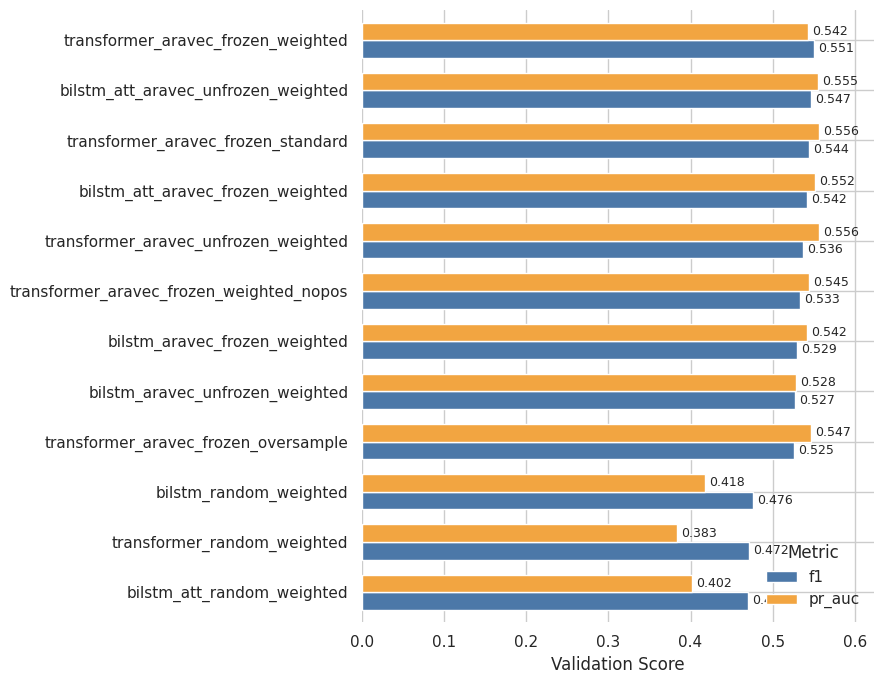

In [37]:
plot_table = results[results["seed"] == 42].set_index("model")[["val_f1", "val_pr_auc"]]
plot_table.columns = ["f1", "pr_auc"]
plot_results(plot_table)

## 11. Download the outputs
Zips results, predictions and checkpoints so they can be saved before the runtime ends.

In [38]:
import shutil
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    for name in ["results", "predictions", "models"]:
        shutil.copytree(ROOT / name, Path(tmp) / name)
    shutil.make_archive("/content/sarcasm_outputs", "zip", tmp)

try:
    from google.colab import files
    files.download("/content/sarcasm_outputs.zip")
except ImportError:
    print("saved to /content/sarcasm_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>